# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the untuned `SCRATCH_HYPERPARAMS`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: NoordelikeWerke
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']


## Data loaders and class weights

In [2]:
cfg = SCRATCH_HYPERPARAMS

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 32)
Train: 1707 | Val: 415 | Test: 405


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 1.00e-04 | train loss 1.1791 acc 0.414 | val loss 1.0118 acc 0.506 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 1.00e-04 | train loss 0.9925 acc 0.502 | val loss 0.9445 acc 0.542 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 1.00e-04 | train loss 1.0500 acc 0.508 | val loss 0.9813 acc 0.530


[ResNet-18 (scratch)] Epoch   4/100 | LR: 1.00e-04 | train loss 0.9719 acc 0.514 | val loss 0.9371 acc 0.554 *


...

[ResNet-18 (scratch)] Epoch  56/100 | LR: 1.00e-07 | train loss 0.4260 acc 0.796 | val loss 0.5462 acc 0.788


[ResNet-18 (scratch)] Epoch  57/100 | LR: 1.00e-07 | train loss 0.4027 acc 0.800 | val loss 0.5490 acc 0.795


[ResNet-18 (scratch)] Epoch  58/100 | LR: 1.00e-07 | train loss 0.4172 acc 0.793 | val loss 0.5499 acc 0.800


[ResNet-18 (scratch)] Epoch  59/100 | LR: 1.00e-07 | train loss 0.4261 acc 0.791 | val loss 0.5392 acc 0.795


[ResNet-18 (scratch)] Epoch  60/100 | LR: 1.00e-08 | train loss 0.3983 acc 0.800 | val loss 0.5382 acc 0.795

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 60.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.5338)


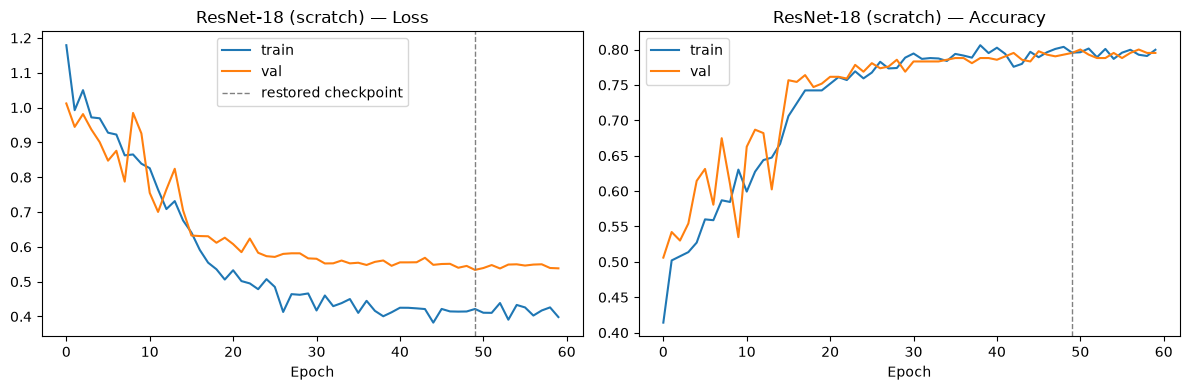

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.825


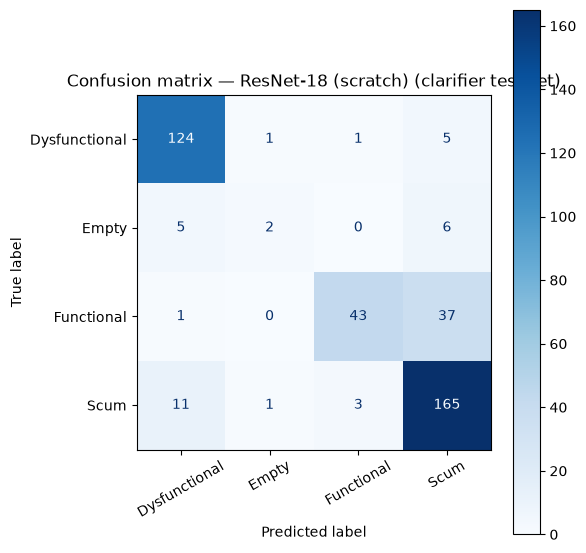

               precision    recall  f1-score   support

Dysfunctional      0.879     0.947     0.912       131
        Empty      0.500     0.154     0.235        13
   Functional      0.915     0.531     0.672        81
         Scum      0.775     0.917     0.840       180

     accuracy                          0.825       405
    macro avg      0.767     0.637     0.665       405
 weighted avg      0.828     0.825     0.810       405



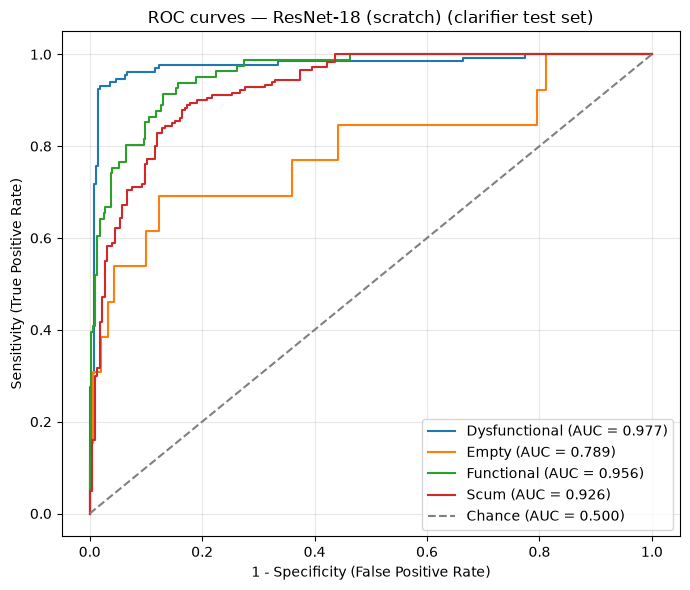

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.977
  Empty          : 0.789
  Functional     : 0.956
  Scum           : 0.926

Mean AUC (over 4/4 classes with test examples): 0.912


(np.float64(0.8246913580246914),
 {'Dysfunctional': 0.9768763581657102,
  'Empty': 0.7892464678178964,
  'Functional': 0.95568510897729,
  'Scum': 0.9262469135802469})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/clarifier_aug/results_clarifier_resnet18_scratch_NoordelikeWerke.pkl
Saved model weights to ../models/pad/clarifier_aug/clarifier_resnet18_scratch_NoordelikeWerke.pt
